# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [1]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [3]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

Estadísticas iniciales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [5]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


Pues que en los datos originales cada columna tiene su propio rango en centímetros, por ejemplo, sepal length va de 4.3 a 7.9, mientras que petal width va de 0.1 a 2.5. Ya después de aplicar MinMaxScaler, todas las columnas quedan ajustadas exacto entre 0 y 1, con mínimo en 0 y máximo en 1. También se reducen y equilibran sus medias porque todas quedan alrededor de 0.43 a 0.47 y sus desviaciones estándar, que quedan entre 0.18 y 0.32, pero manteniendo la proporción relativa entre los valores.

In [6]:
print("Estadísticas originales:")
display(data.describe().round(4))

print("\nEstadísticas con MinMaxScaler:")
display(data_minmax.describe().round(4))

Estadísticas originales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.0000,150.0000,150.0000,150.0000
mean,5.8433,3.0573,3.7580,1.1993
std,0.8281,0.4359,1.7653,0.7622
min,4.3000,2.0000,1.0000,0.1000
25%,5.1000,2.8000,1.6000,0.3000
50%,5.8000,3.0000,4.3500,1.3000
75%,6.4000,3.3000,5.1000,1.8000
max,7.9000,4.4000,6.9000,2.5000



Estadísticas con MinMaxScaler:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.0000,150.0000,150.0000,150.0000
mean,0.4287,0.4406,0.4675,0.4581
std,0.2300,0.1816,0.2992,0.3176
min,0.0000,0.0000,0.0000,0.0000
25%,0.2222,0.3333,0.1017,0.0833
50%,0.4167,0.4167,0.5678,0.5000
75%,0.5833,0.5417,0.6949,0.7083
max,1.0000,1.0000,1.0000,1.0000


### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

En los histogramas se observa que la forma de la distribución de sepal length (cm) no cambia después de escalar los datos. Lo único que cambia es la escala del eje horizontal, o sea en los datos originales va de 4.3 a 7.9 cm, con MinMaxScaler queda entre 0 y 1, y con StandardScaler queda centrada alrededor de 0, entre -1.87 y 2.49.

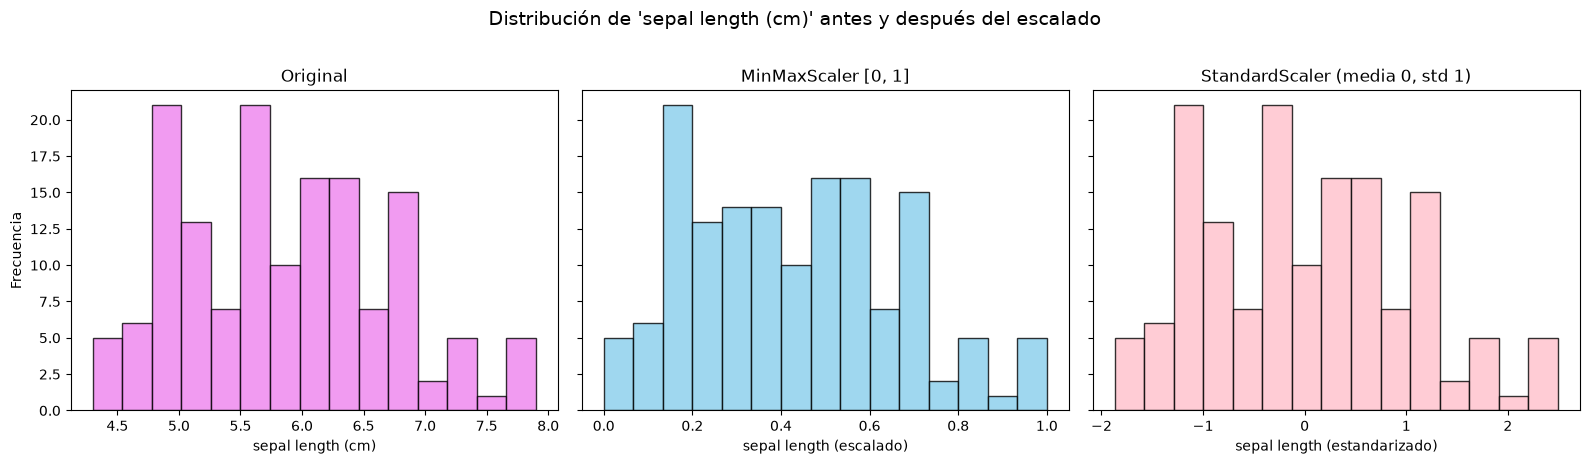

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
col = "sepal length (cm)"

# Original
axes[0].hist(data[col], bins=15, color="violet", edgecolor="black", alpha=0.8)
axes[0].set_title("Original")
axes[0].set_xlabel("sepal length (cm)")
axes[0].set_ylabel("Frecuencia")

# MinMaxScaler
axes[1].hist(data_minmax[col], bins=15, color="skyblue", edgecolor="black", alpha=0.8)
axes[1].set_title("MinMaxScaler [0, 1]")
axes[1].set_xlabel("sepal length (escalado)")

# StandardScaler
axes[2].hist(data_standard[col], bins=15, color="pink", edgecolor="black", alpha=0.8)
axes[2].set_title("StandardScaler (media 0, std 1)")
axes[2].set_xlabel("sepal length (estandarizado)")

plt.suptitle(
    "Distribución de 'sepal length (cm)' antes y después del escalado",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

Mi gráfica de dispersión muestra la relación entre sepal length y sepal width ya estandarizados. Ambos ejes quedan centrados en 0 y con la misma escala, manteniendo asi intacta la posición relativa de los puntos y la separación natural entre las especies de iris.

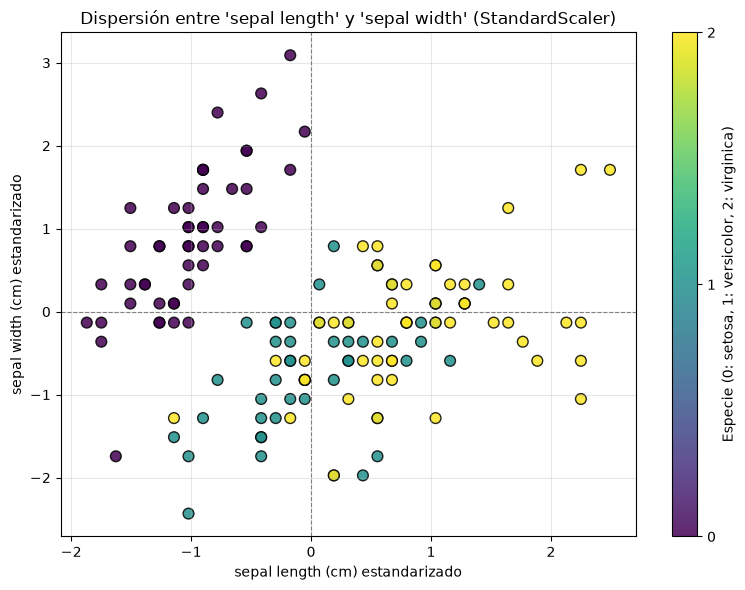

In [8]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    data_standard["sepal length (cm)"],
    data_standard["sepal width (cm)"],
    c=iris.target,
    cmap="viridis",
    edgecolor="black",
    s=60,
    alpha=0.85,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Dispersión entre 'sepal length' y 'sepal width' (StandardScaler)")
plt.xlabel("sepal length (cm) estandarizado")
plt.ylabel("sepal width (cm) estandarizado")
plt.colorbar(
    scatter, ticks=[0, 1, 2], label="Especie (0: setosa, 1: versicolor, 2: virginica)"
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

Creo que la técnica más adecuada para este conjunto de datos es StandardScaler porque las cuatro variables de iris son medidas continuas sin valores atípicos extremos o sea solo algunos valores ligeramente altos o bajos en sepal width, y al estandarizarlas todas quedan con media 0 y desviación estándar igual a 1 y esto evita que las columnas con rangos más grandes dominen sobre las demás al usar algoritmos. MinMaxScaler también funciona bien, pero se supone que suele ser mejor cuando un modelo exige valores estrictamente entre 0 y 1.

Estadísticas con StandardScaler:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.0000,150.0000,150.0000,150.0000
mean,-0.0000,-0.0000,-0.0000,-0.0000
std,1.0034,1.0034,1.0034,1.0034
min,-1.8700,-2.4339,-1.5676,-1.4471
25%,-0.9007,-0.5924,-1.2266,-1.1838
50%,-0.0525,-0.1320,0.3365,0.1325
75%,0.6745,0.5586,0.7628,0.7907
max,2.4920,3.0908,1.7858,1.7121


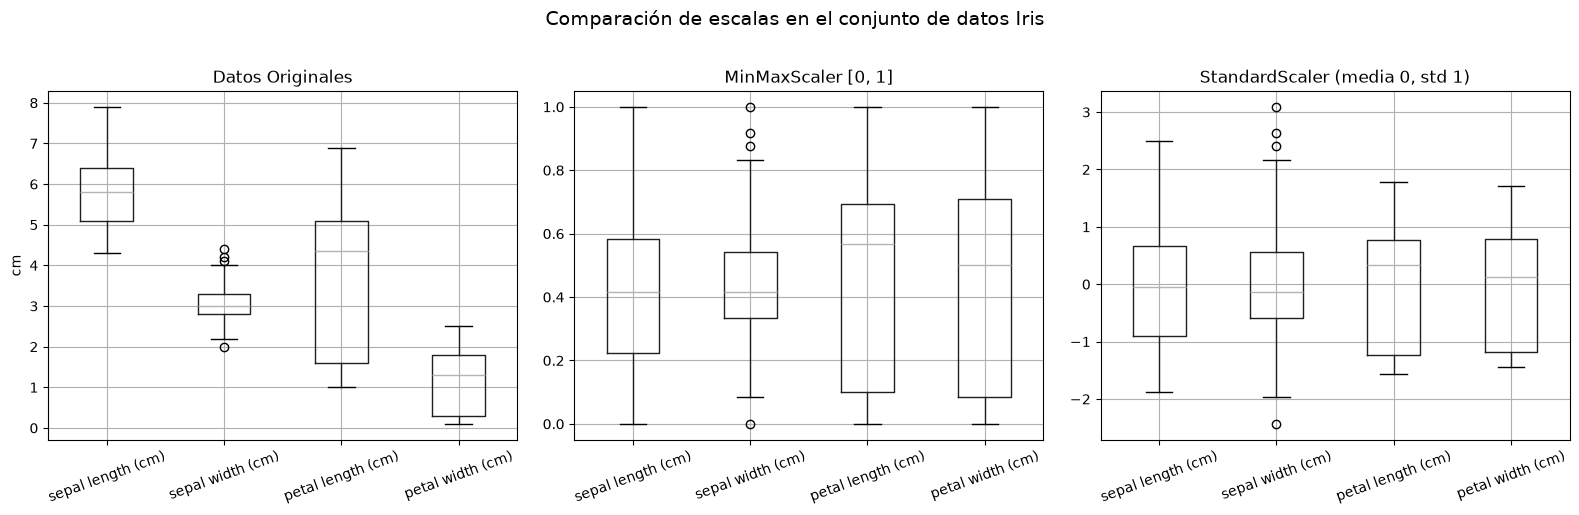

In [9]:
print("Estadísticas con StandardScaler:")
display(data_standard.describe().round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

data.boxplot(ax=axes[0], rot=20)
axes[0].set_title("Datos Originales")
axes[0].set_ylabel("cm")

data_minmax.boxplot(ax=axes[1], rot=20)
axes[1].set_title("MinMaxScaler [0, 1]")

data_standard.boxplot(ax=axes[2], rot=20)
axes[2].set_title("StandardScaler (media 0, std 1)")

plt.suptitle("Comparación de escalas en el conjunto de datos Iris", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()